In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("car data.csv")

print("Dataset Loaded Successfully!")

display(df.head())

Dataset Loaded Successfully!


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (301, 9)

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Statistical Summary:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000



Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


In [5]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df = df.dropna()

print("Data Cleaning Completed!")

print("Final Dataset Shape:", df.shape)

Data Cleaning Completed!
Final Dataset Shape: (299, 9)


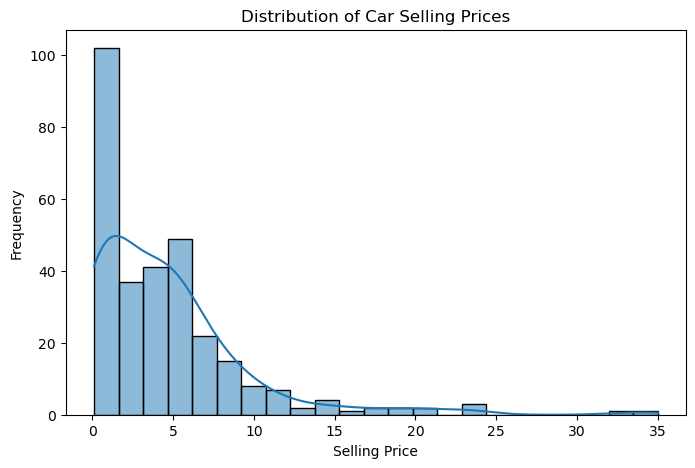

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['Selling_Price'],
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

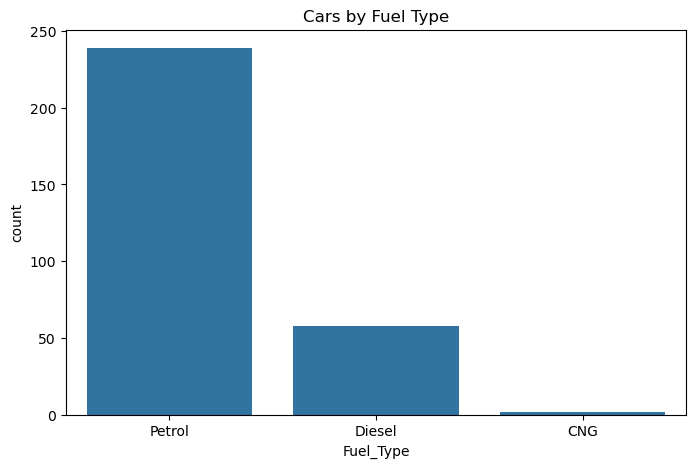

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Fuel_Type'
)

plt.title("Cars by Fuel Type")
plt.show()

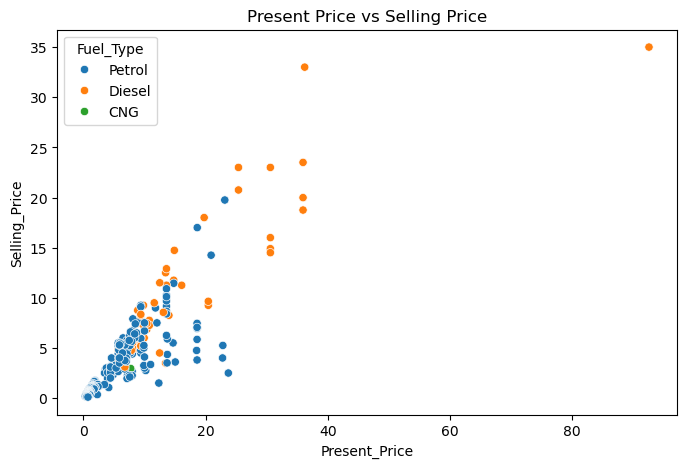

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Present_Price',
    y='Selling_Price',
    hue='Fuel_Type'
)

plt.title("Present Price vs Selling Price")
plt.show()

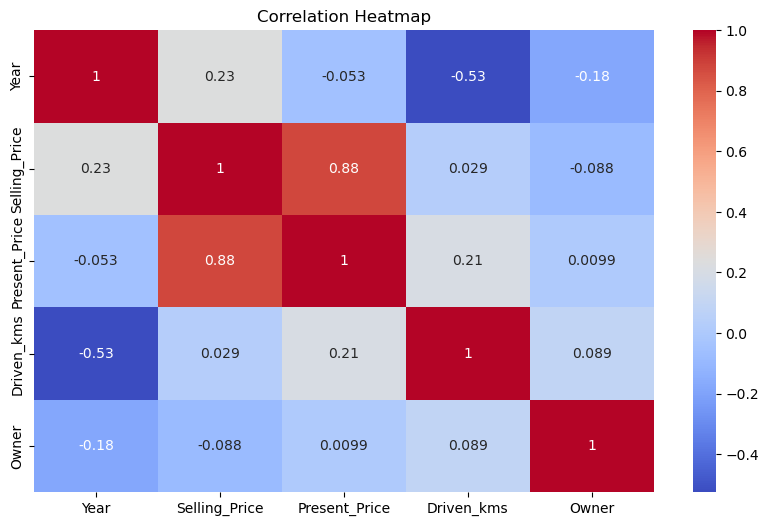

In [9]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

In [10]:
# Remove target and unnecessary car name
X = df.drop(
    ['Selling_Price', 'Car_Name'],
    axis=1
)

y = df['Selling_Price']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   Year  Present_Price  Driven_kms Fuel_Type Selling_type Transmission  Owner
0  2014           5.59       27000    Petrol       Dealer       Manual      0
1  2013           9.54       43000    Diesel       Dealer       Manual      0
2  2017           9.85        6900    Petrol       Dealer       Manual      0
3  2011           4.15        5200    Petrol       Dealer       Manual      0
4  2014           6.87       42450    Diesel       Dealer       Manual      0

Target Variable:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (239, 7)
Testing Data: (60, 7)


In [12]:
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['Fuel_Type', 'Selling_type', 'Transmission']
Numerical Features: ['Year', 'Present_Price', 'Driven_kms', 'Owner']


In [13]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = {}
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    r2 = r2_score(y_test, predictions)

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    results[name] = {
        'R2 Score': r2,
        'MAE': mae,
        'RMSE': rmse
    }

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("R2 Score:", round(r2, 4))
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))


Model: Linear Regression
R2 Score: 0.7527
MAE: 1.4725
RMSE: 2.5245

Model: Decision Tree
R2 Score: 0.8359
MAE: 1.0968
RMSE: 2.0566

Model: Random Forest
R2 Score: 0.5533
MAE: 1.4297
RMSE: 3.3932


In [14]:
results_df = pd.DataFrame(results).T

display(results_df)

,R2 Score,MAE,RMSE
Linear Regression,0.752723,1.472546,2.524505
Decision Tree,0.835890,1.096833,2.056608
Random Forest,0.553275,1.429745,3.393163


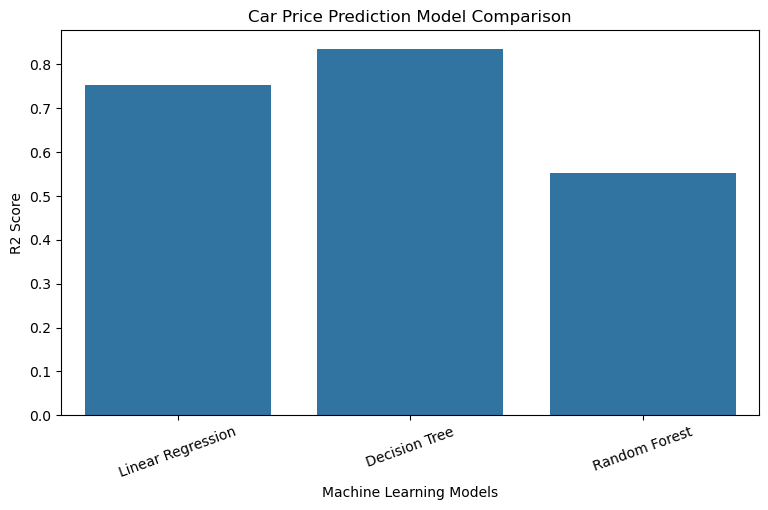

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=results_df.index,
    y=results_df['R2 Score']
)

plt.title("Car Price Prediction Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)

plt.show()

In [16]:
best_model_name = results_df['R2 Score'].idxmax()

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Best R2 Score:",
    round(results_df.loc[best_model_name, 'R2 Score'], 4)
)

Best Model: Decision Tree
Best R2 Score: 0.8359


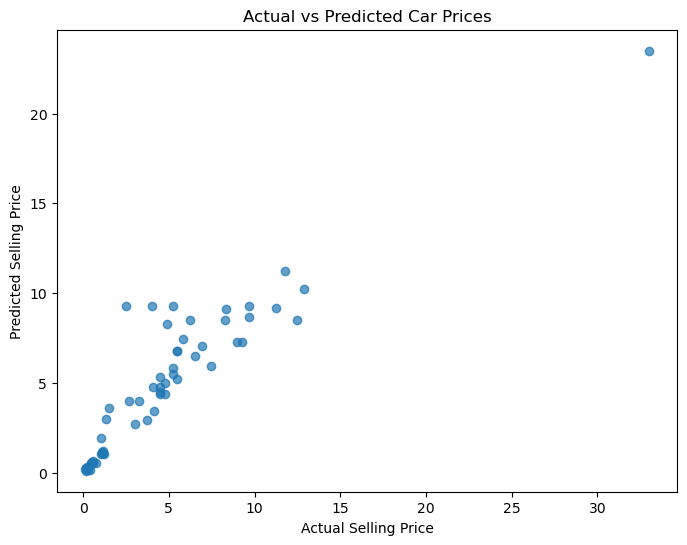

In [17]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

In [21]:
print("=" * 50)
print("CAR PRICE PREDICTION PROJECT")
print("=" * 50)

print("Total Records:", len(df))

print("Total Features:", X.shape[1])

print("\nModels Evaluated:")

for name, values in results.items():

    print("\n", name)

    print("R2 Score:", round(values['R2 Score'], 4))

    print("MAE:", round(values['MAE'], 4))

    print("RMSE:", round(values['RMSE'], 4))

print("\nBest Model:", best_model_name)

print("\nProject Completed Successfully!")

CAR PRICE PREDICTION PROJECT
Total Records: 299
Total Features: 7

Models Evaluated:

 Linear Regression
R2 Score: 0.7527
MAE: 1.4725
RMSE: 2.5245

 Decision Tree
R2 Score: 0.8359
MAE: 1.0968
RMSE: 2.0566

 Random Forest
R2 Score: 0.5533
MAE: 1.4297
RMSE: 3.3932

Best Model: Decision Tree

Project Completed Successfully!
